	Predicting Stock Market Prices	Generate an extensive set of descriptive statistical reports for key stock metrics including Open, High, Low, Close, Adj Close, and Volume, facilitating in-depth exploratory data analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv(
    "TSLA_cleaned_data.csv",
    parse_dates=["Date"]
)

print("Dataset Shape:", data.shape)
display(data.head())

Dataset Shape: (100, 6)


,Date,Open,High,Low,Close,Volume
0,2025-04-29,402.54,404.82,400.82,402.89,96503640
1,2025-03-18,414.37,417.58,406.36,411.17,129923902
2,2025-04-10,406.52,410.38,403.81,409.23,113709729
3,2025-03-06,405.40,405.98,399.78,404.15,119732002
4,2025-03-05,411.49,415.52,399.13,402.75,48754535


In [3]:
metrics = [
    "Open", "High", "Low",
    "Close", "Adj Close", "Volume"
]

available_metrics = [
    col for col in metrics if col in data.columns
]

missing_metrics = [
    col for col in metrics if col not in data.columns
]

print("Available Metrics:", available_metrics)
print("Missing Metrics:", missing_metrics)

Available Metrics: ['Open', 'High', 'Low', 'Close', 'Volume']
Missing Metrics: ['Adj Close']


In [4]:
for col in available_metrics:
    data[col] = pd.to_numeric(data[col], errors="coerce")

print("Data type conversion completed.")

display(data[available_metrics].dtypes)

Data type conversion completed.


Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

In [5]:
descriptive_report = data[available_metrics].describe().T

display(descriptive_report)

,count,mean,std,min,25%,50%,75%,max
Open,100.0,3.959426e+02,1.504756e+01,360.74,3.818475e+02,4.009250e+02,4.065300e+02,4.187100e+02
High,100.0,3.998103e+02,1.496859e+01,366.30,3.856775e+02,4.047800e+02,4.109150e+02,4.237700e+02
Low,100.0,3.919425e+02,1.483533e+01,356.63,3.786575e+02,3.968300e+02,4.020625e+02,4.147500e+02
Close,100.0,3.961875e+02,1.470973e+01,363.54,3.817900e+02,4.010100e+02,4.068100e+02,4.205500e+02
Volume,100.0,8.590925e+07,2.814561e+07,45415699.00,5.631168e+07,8.569552e+07,1.130929e+08,1.299239e+08


In [6]:
additional_stats = pd.DataFrame({
    "Mean": data[available_metrics].mean(),
    "Median": data[available_metrics].median(),
    "Mode": data[available_metrics].mode().iloc[0],
    "Variance": data[available_metrics].var(),
    "Standard Deviation": data[available_metrics].std(),
    "Skewness": data[available_metrics].skew(),
    "Kurtosis": data[available_metrics].kurt()
})

display(additional_stats.round(3))

,Mean,Median,Mode,Variance,Standard Deviation,Skewness,Kurtosis
Open,3.959430e+02,4.009250e+02,370.25,2.264290e+02,1.504800e+01,-0.526,-0.927
High,3.998100e+02,4.047800e+02,375.12,2.240590e+02,1.496900e+01,-0.492,-0.941
Low,3.919420e+02,3.968300e+02,363.13,2.200870e+02,1.483500e+01,-0.547,-0.819
Close,3.961880e+02,4.010100e+02,368.04,2.163760e+02,1.471000e+01,-0.483,-0.915
Volume,8.590925e+07,8.569552e+07,53132590.00,7.921752e+14,2.814561e+07,-0.013,-1.479


In [7]:
outlier_report = {}

for col in available_metrics:

    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = data[
        (data[col] < lower_limit) |
        (data[col] > upper_limit)
    ]

    outlier_report[col] = len(outliers)

outlier_report = pd.DataFrame.from_dict(
    outlier_report,
    orient="index",
    columns=["Outlier Count"]
)

display(outlier_report)

,Outlier Count
Open,0
High,0
Low,0
Close,0
Volume,0


In [8]:
correlation = data[available_metrics].corr()

display(correlation.round(3))

,Open,High,Low,Close,Volume
Open,1.000,0.990,0.988,0.981,-0.060
High,0.990,1.000,0.983,0.988,-0.065
Low,0.988,0.983,1.000,0.989,-0.060
Close,0.981,0.988,0.989,1.000,-0.076
Volume,-0.060,-0.065,-0.060,-0.076,1.000


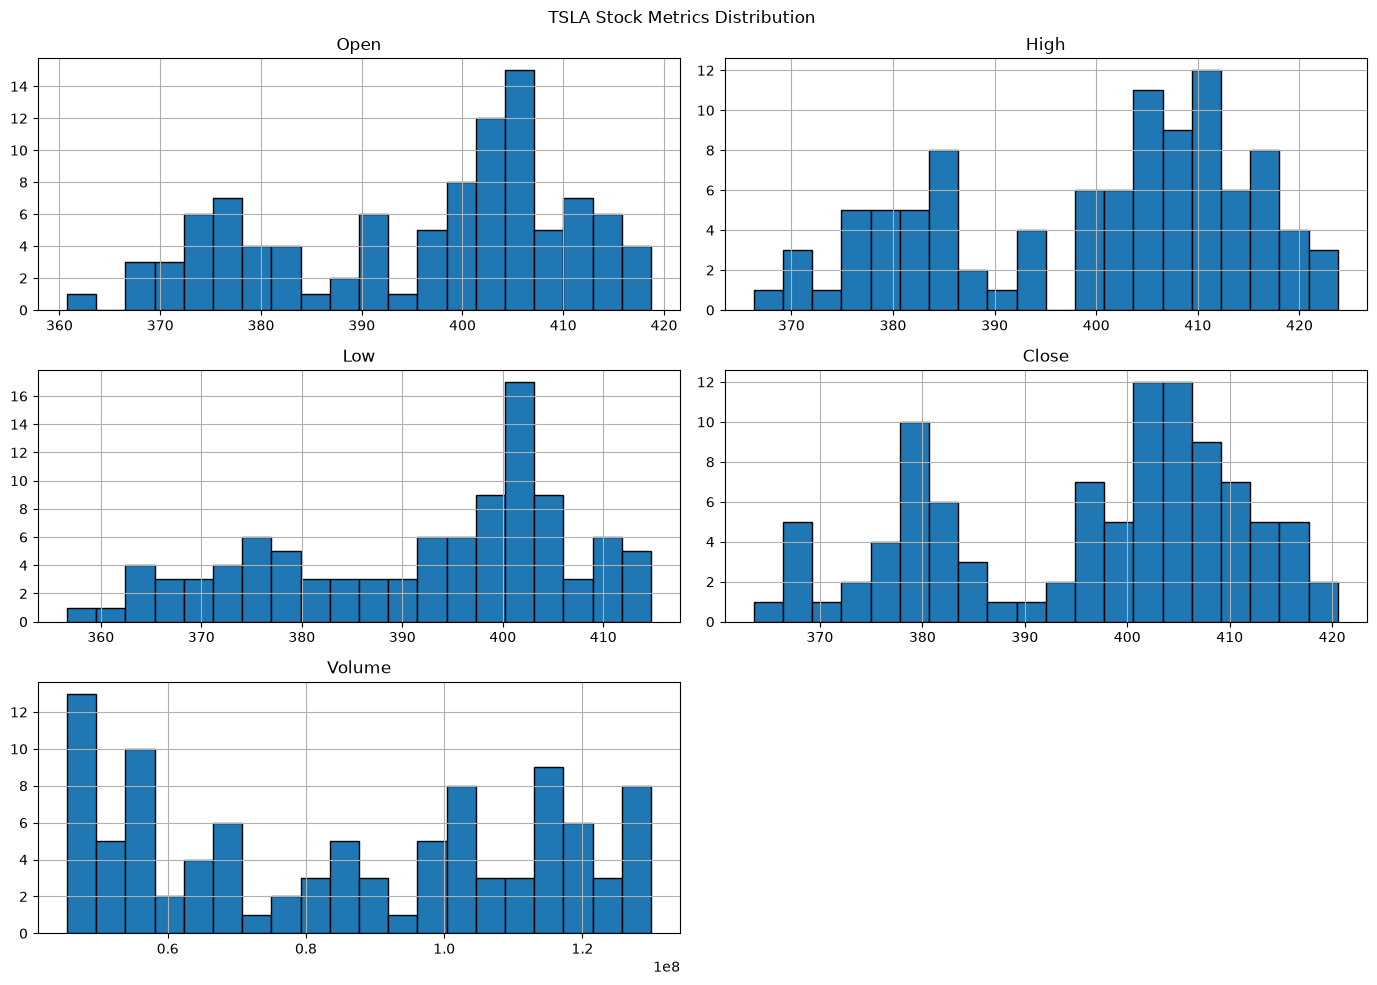

In [9]:
data[available_metrics].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("TSLA Stock Metrics Distribution")
plt.tight_layout()
plt.show()

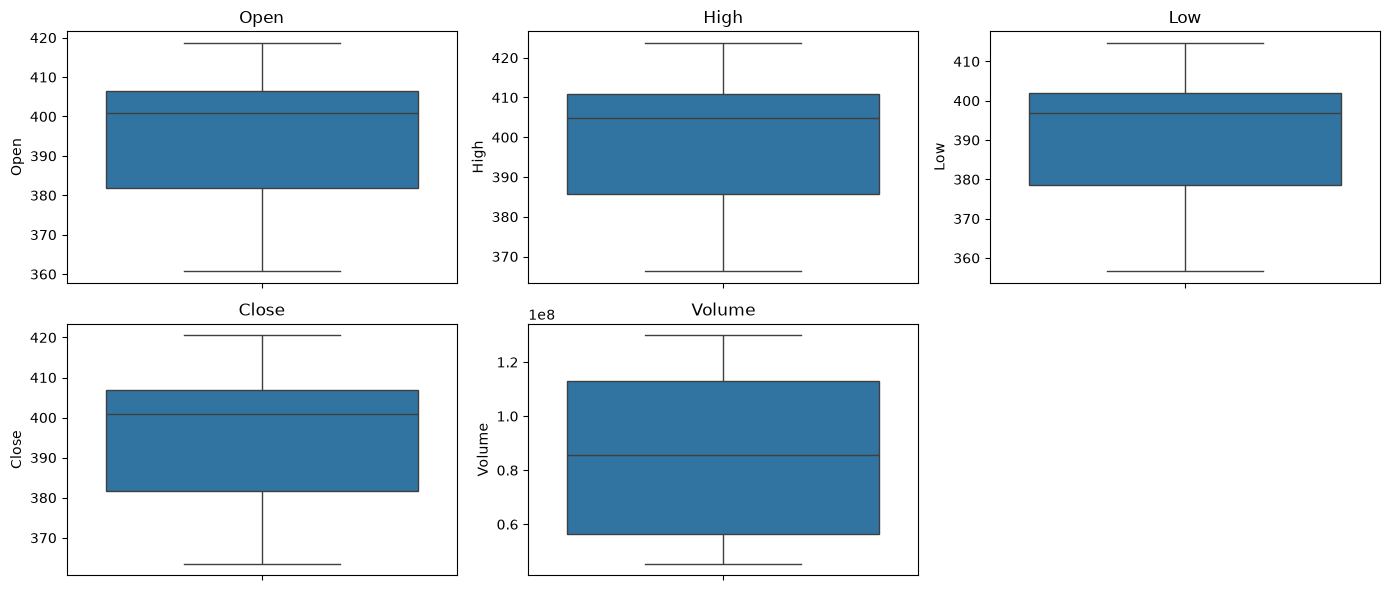

In [10]:
plt.figure(figsize=(14, 6))

for i, col in enumerate(available_metrics, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=data[col])
    plt.title(col)

plt.tight_layout()
plt.show()

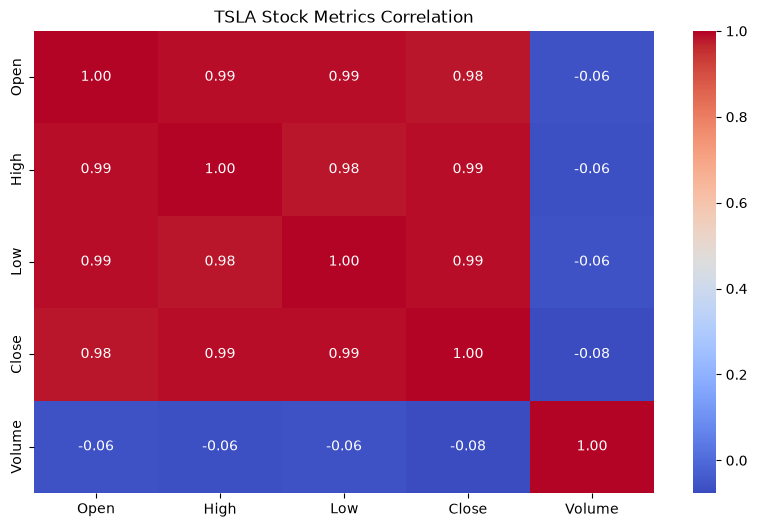

In [11]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("TSLA Stock Metrics Correlation")
plt.show()